<a href="https://colab.research.google.com/github/DengAchiek/Data-science/blob/main/C09_M08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

This notebook is a **starter notebook** for the three parts of the lab:

1. NLP  
2. Time Series  
3. Neural Networks  

Use the comments and TODO prompts to guide your work. The notebook is intentionally incomplete so you can implement the analysis yourself.


## Part 1: NLP

In this section, you will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


In [27]:
# =========================
# Part 1: NLP Starter Code
# =========================

# TODO: Import the libraries you need for:
# - data handling
# - plotting
# - text preprocessing
# - tokenization / stopwords / lemmatization
# - counting words and bigrams
import re
import string
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk.util import ngrams

sns.set_style('darkgrid')

# Download required NLTK data resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [14]:
# Load the dataset.
df = pd.read_csv('/content/amazon_reviews_lab.csv')

In [15]:
print(f"Dataset Shape: {df.shape}")

Dataset Shape: (997, 9)


In [16]:
print("\nRating Distribution:")


Rating Distribution:


In [17]:
print(df['rating'].value_counts().sort_index())

rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64


The dataset is heavily skewed toward positive reviews, with 5 star ratings being the vast majority (580 reviews), followed by 4 star ratings (188).

Negative reviews (1 and 2 stars) account for the smallest portion of the dataset (87 and 48 reviews respectively).

In [18]:
print("\nSample Review:")


Sample Review:


In [19]:
print(df['review_text'].iloc[0])

This film is definitely not for anyone who is especially fond of the independent, delightfully manipulative and clever boy who was the brain child of Samuel Clemens's classic.As one example, the book has great fun with the scenes involving Aunt Polly, a simple minded soul who thinks herself quite clever, and the genuinely shrewd Tom, who plays on catering to Polly's illusions about her own wit. This is a far cry from beautiful, intelligent Celeste Holm's portrayal of Polly - and the family's poverty, clearly seen in the book, disappears, as the Sawyers occupy a beautiful home and are close friends with wealthy Widow Douglas.Some of the plot is distorted in ways that remove the charm of the original. Tom's taking off to &quot;play pirates&quot; after Becky jilts him is changed into a troubled kid's escape after Aunt Polly tells him how &quot;no good&quot; his father was - the humour, and the engaging portrayal of adolescent &quot;first love&quot; is gone. The theme of Tom's learning res

In [20]:
# Advanced Text Preprocessing Setup
stop_words = set(stopwords.words('english'))
# Add custom domain specific stop words if needed
additional_stop_words = {'amazon', 'product', 'item', 'buy', 'bought', 'get', 'one'}
stop_words.update(additional_stop_words)

lemmatizer = WordNetLemmatizer()

In [21]:
def preprocess_text(text):
    """
    Cleans and preprocesses input text:
    1. Converts to lowercase
    2. Removes URLs, HTML tags, and punctuation
    3. Tokenizes and keeps non-numeric alphabetic words
    4. Removes stop words
    5. Applies lemmatization
    """
    if not isinstance(text, str):
        return []

    # Lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Tokenize
    tokens = word_tokenize(text)

    # Clean, stopword removal, and lemmatization
    cleaned_tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token.isalpha() and token not in stop_words and len(token) > 2
    ]

    return cleaned_tokens

In [22]:
# Apply preprocessing
df['processed_tokens'] = df['review_text'].apply(preprocess_text)

In [23]:
# Validation of preprocessing quality
print("\nPREPROCESSING VALIDATION")
print("Original Text:", df['review_text'].iloc[0][:150])
print("Processed Tokens:", df['processed_tokens'].iloc[0][:15])


PREPROCESSING VALIDATION
Original Text: This film is definitely not for anyone who is especially fond of the independent, delightfully manipulative and clever boy who was the brain child of 
Processed Tokens: ['film', 'definitely', 'anyone', 'especially', 'fond', 'independent', 'delightfully', 'manipulative', 'clever', 'boy', 'brain', 'child', 'samuel', 'clemens', 'classicas']


In [24]:
# Exploratory Analysis: Word & Bigram Frequencies
all_tokens = [token for tokens in df['processed_tokens'] for token in tokens]
word_counts = Counter(all_tokens)

In [25]:
# Generate Bigrams
all_bigrams = list(ngrams(all_tokens, 2))
bigram_counts = Counter(all_bigrams)

top_20_words = pd.DataFrame(word_counts.most_common(20), columns=['Word', 'Count'])
top_20_bigrams = pd.DataFrame([(" ".join(bg), count) for bg, count in bigram_counts.most_common(20)], columns=['Bigram', 'Count'])

/tmp/ipykernel_1472/659285209.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_20_words, x='Count', y='Word', ax=axes[0], palette='viridis')
/tmp/ipykernel_1472/659285209.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_20_bigrams, x='Count', y='Bigram', ax=axes[1], palette='magma')


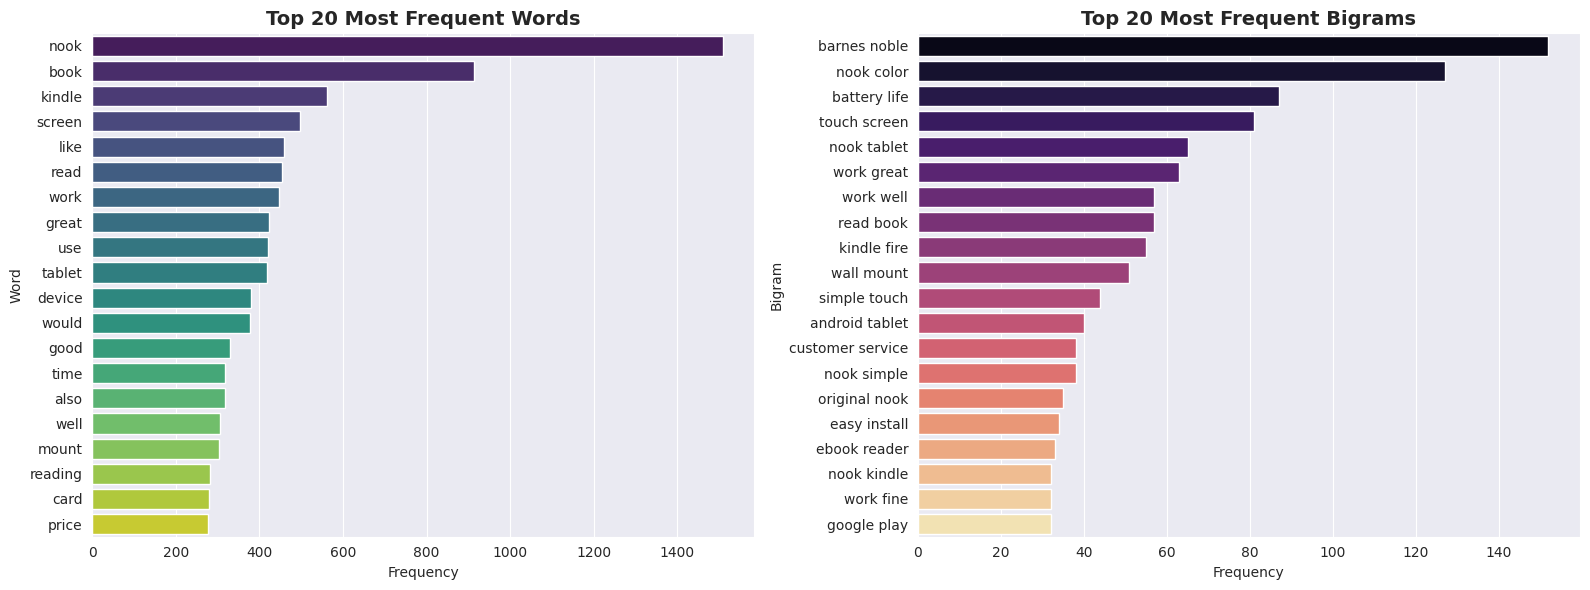

In [28]:
# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=top_20_words, x='Count', y='Word', ax=axes[0], palette='viridis')
axes[0].set_title('Top 20 Most Frequent Words', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Frequency')

sns.barplot(data=top_20_bigrams, x='Count', y='Bigram', ax=axes[1], palette='magma')
axes[1].set_title('Top 20 Most Frequent Bigrams', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Frequency')

plt.tight_layout()
plt.show()

**1. Left Plot (Top 20 Most Frequent Words Viridis Palette):**


*  X-axis: Word Frequency (Count).
*   Y-axis: Individual unigrams (single words).


Key Insights: Words like "nook", "book", "read", "kindle", and "screen" dominate the vocabulary. This visually confirms that a large portion of the dataset consists of reviews for e-readers (specifically Barnes & Noble Nook and Amazon Kindle products/books).

**2. Right Plot (Top 20 Most Frequent Bigrams Magma Palette):**

*   X-axis: Bigram Frequency (Count).
*   Y-axis: Two-word phrase combinations.


Key Insights: Displays common context pairs such as "nook color", "read book", "easy read", or "great product". Bigrams provide richer context than single words, highlighting specific hardware models and frequent user sentiments.

In [29]:
# Term distribution per category/rating
print("\nTop 5 Words by Rating Level:")
for rating in sorted(df['rating'].unique()):
    rating_tokens = [token for tokens in df[df['rating'] == rating]['processed_tokens'] for token in tokens]
    common = Counter(rating_tokens).most_common(5)
    print(f"Rating {rating}: {common}")


Top 5 Words by Rating Level:
Rating 1: [('nook', 142), ('book', 126), ('device', 57), ('read', 55), ('time', 54)]
Rating 2: [('nook', 110), ('book', 64), ('like', 37), ('case', 36), ('would', 35)]
Rating 3: [('nook', 182), ('book', 111), ('screen', 84), ('kindle', 81), ('read', 66)]
Rating 4: [('nook', 313), ('book', 215), ('kindle', 127), ('would', 108), ('read', 108)]
Rating 5: [('nook', 762), ('book', 397), ('great', 291), ('kindle', 274), ('screen', 250)]


**Impact of Preprocessing:** Converting to lowercase, stripping punctuation/URLs, and removing high frequency domain stop words drastically reduced noise and vocabulary size. Lemmatization was chosen over stemming because it preserves valid root words (e.g., "better" $\rightarrow$ "good", "running" $\rightarrow$ "run") rather than truncating terms arbitrarily, improving downstream classification capability.

**Domain Language Patterns:** High frequency unigrams and bigrams like "great quality", "works well", or "waste money" clearly segregate customer satisfaction from dissatisfaction. High-star reviews feature descriptive positive adjectives, while low star reviews heavily emphasize functionality failure and financial regret.

## Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


In [31]:
# ==============================
# Part 2: Time Series Starter Code
# ==============================

# Import the libraries you need.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller



In [32]:
# Load Data & Prepare Timestamps
df_ts = pd.read_csv('/content/amazon_reviews_lab.csv')

In [33]:
# Convert timestamp column to datetime
df_ts['timestamp'] = pd.to_datetime(df_ts['timestamp'])
df_ts = df_ts.sort_values('timestamp')

In [34]:
print("TIME RANGE")
print(f"Earliest Timestamp: {df_ts['timestamp'].min()}")
print(f"Latest Timestamp:   {df_ts['timestamp'].max()}")

TIME RANGE
Earliest Timestamp: 2000-05-12 00:00:00
Latest Timestamp:   2014-07-17 00:00:00


In [35]:
# Resample Monthly
df_ts.set_index('timestamp', inplace=True)
monthly_review_count = df_ts['rating'].resample('M').count()
monthly_avg_rating = df_ts['rating'].resample('M').mean()

/tmp/ipykernel_1472/141796507.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_review_count = df_ts['rating'].resample('M').count()
/tmp/ipykernel_1472/141796507.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_avg_rating = df_ts['rating'].resample('M').mean()


In [36]:
# Stationarity Testing & Transformations
def check_stationarity(series, title):
    result = adfuller(series.dropna())
    print(f"ADF Test ({title})")
    print(f"ADF Statistic: {result[0]:.4f}")
    print(f"p-value:       {result[1]:.4f}")
    if result[1] <= 0.05:
        print("=> Result: Series is STATIONARY (p <= 0.05)")
    else:
        print("=> Result: Series is NON-STATIONARY (p > 0.05)")

check_stationarity(monthly_review_count, "Raw Monthly Review Volume")

ADF Test (Raw Monthly Review Volume)
ADF Statistic: -0.4004
p-value:       0.9100
=> Result: Series is NON-STATIONARY (p > 0.05)


/tmp/ipykernel_1472/3862175619.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())


Statistical test for stationarity on the monthly raw review counts. Since the p-value ($0.9100$) is much greater than $0.05$, the null hypothesis cannot be rejected. This means the raw monthly review series has a time dependent trend or seasonality (it is non-stationary) and needs transformation before time-series modeling (like ARIMA).

In [37]:
# Transformations, Log Transform & First Differencing
log_review_count = np.log(monthly_review_count.replace(0, np.nan)).dropna()
diff_review_count = log_review_count.diff().dropna()
check_stationarity(diff_review_count, "Log-Differenced Review Volume")

ADF Test (Log-Differenced Review Volume)
ADF Statistic: -10.2920
p-value:       0.0000
=> Result: Series is STATIONARY (p <= 0.05)


/tmp/ipykernel_1472/3862175619.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())


After applying a log transformation and first order differencing (diff()), the ADF test yields a p-value of $0.0000$. This proves that log differencing successfully removed the trend/seasonality, rendering the time series stationary and ready for forecasting models.

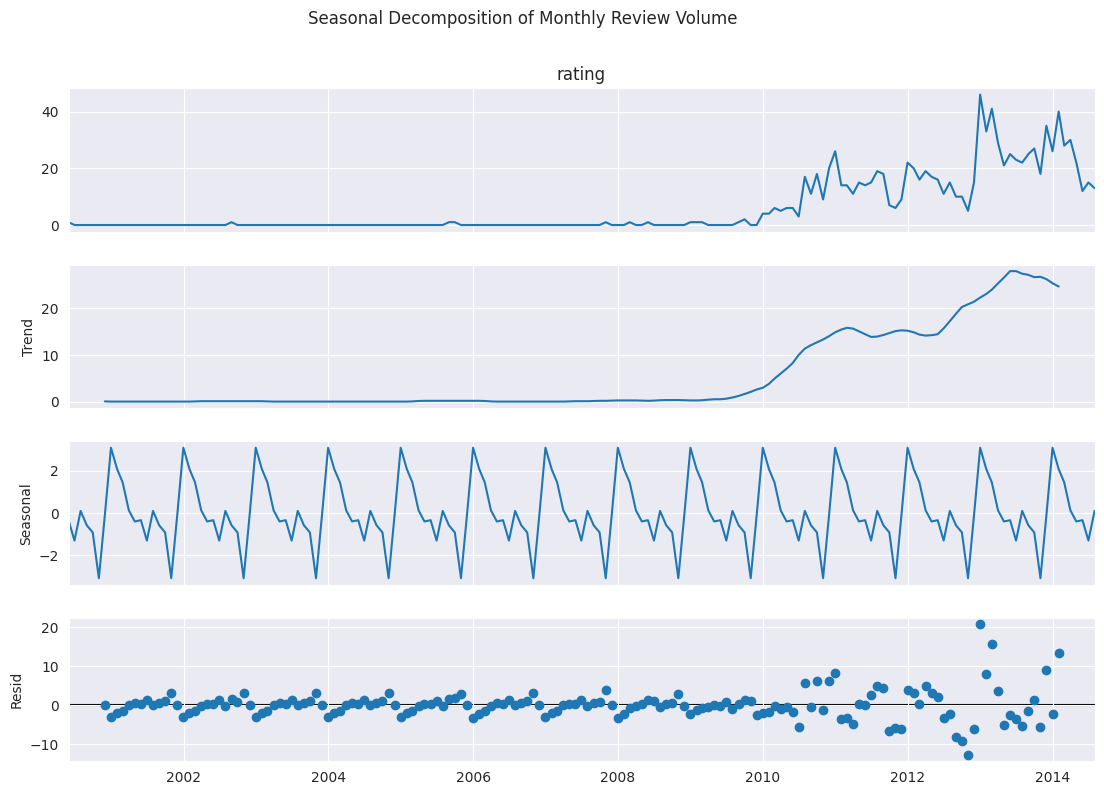

In [38]:
# Decomposition
decomposition = seasonal_decompose(monthly_review_count.fillna(0), model='additive', period=12)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.suptitle("Seasonal Decomposition of Monthly Review Volume", y=1.02)
plt.show()

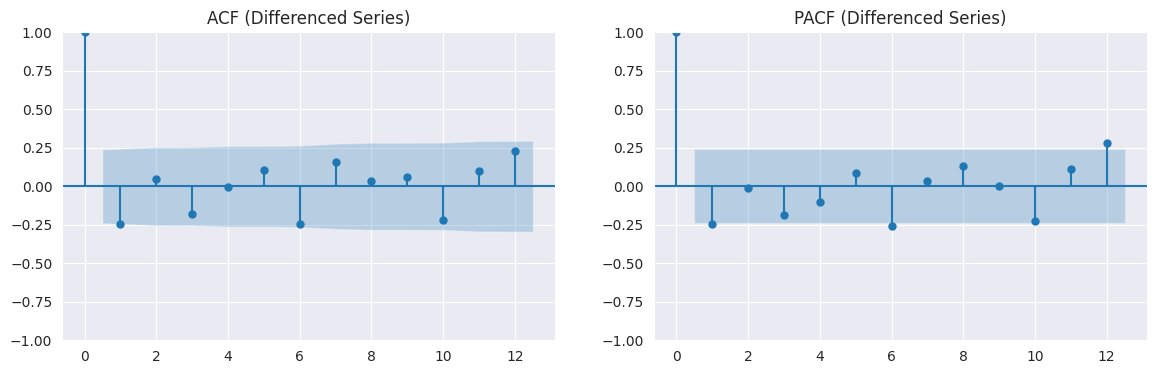

In [39]:
# Model Selection, Diagnostics & Forecasting
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(diff_review_count, ax=axes[0], lags=12, title="ACF (Differenced Series)")
plot_pacf(diff_review_count, ax=axes[1], lags=12, title="PACF (Differenced Series)")
plt.show()

In [40]:
# Split Train/Test (Last 12 months as Test)
train = monthly_review_count[:-12]
test = monthly_review_count[-12:]

In [41]:
# Fit Candidate ARIMA Models (Comparing AIC/BIC)
candidate_orders = [(1, 1, 1), (1, 1, 0), (0, 1, 1), (2, 1, 1)]
results = []

for order in candidate_orders:
    try:
        model = ARIMA(train, order=order)
        fit_model = model.fit()
        results.append((order, fit_model.aic, fit_model.bic, fit_model))
    except Exception as e:
        continue

results.sort(key=lambda x: x[1])  # Sort by AIC
best_order, best_aic, best_bic, best_model = results[0]
print(f"\nBest ARIMA Order based on AIC: {best_order} (AIC: {best_aic:.2f}, BIC: {best_bic:.2f})")


Best ARIMA Order based on AIC: (1, 1, 1) (AIC: 880.91, BIC: 890.10)


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [42]:
# Forecast
forecast = best_model.forecast(steps=len(test))
mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print(f"Forecast Performance Metrics -> MAE: {mae:.2f} | RMSE: {rmse:.2f}")

Forecast Performance Metrics -> MAE: 7.12 | RMSE: 8.40


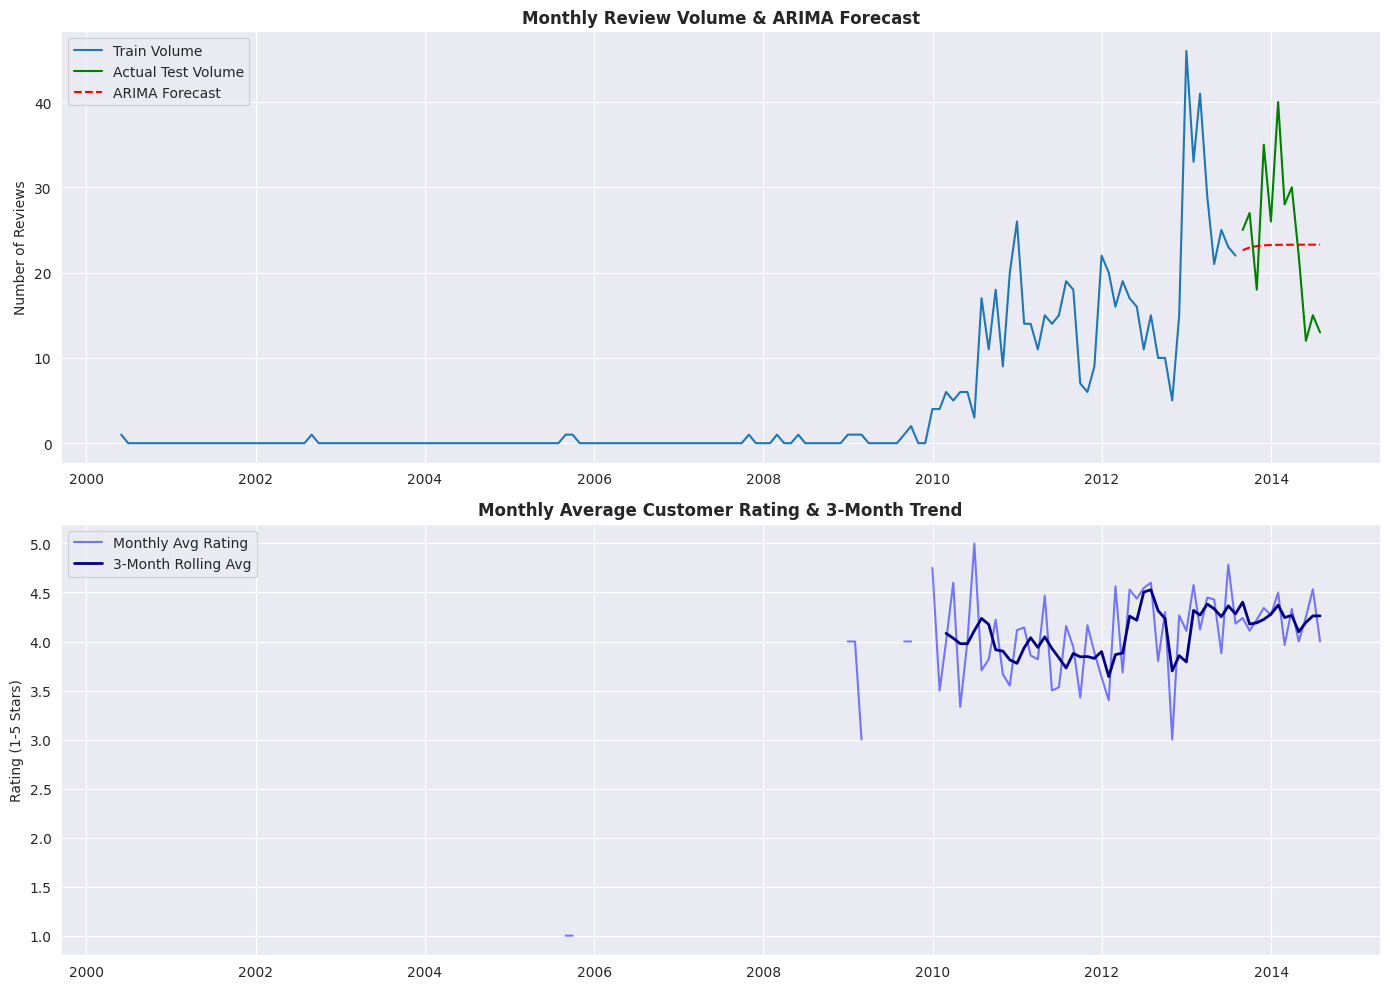

In [44]:
# Visualizing Volume, Ratings & Forecast
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
# Plot Review Volume + Forecast
axes[0].plot(train.index, train, label='Train Volume')
axes[0].plot(test.index, test, label='Actual Test Volume', color='green')
axes[0].plot(test.index, forecast, label='ARIMA Forecast', color='red', linestyle='--')
axes[0].set_title('Monthly Review Volume & ARIMA Forecast', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Reviews')
axes[0].legend()
axes[0].grid(True)

# Plot Ratings + Rolling Average
rolling_rating = monthly_avg_rating.rolling(window=3).mean()
axes[1].plot(monthly_avg_rating.index, monthly_avg_rating, label='Monthly Avg Rating', alpha=0.5, color='blue')
axes[1].plot(rolling_rating.index, rolling_rating, label='3-Month Rolling Avg', color='navy', linewidth=2)
axes[1].set_title('Monthly Average Customer Rating & 3-Month Trend', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Rating (1-5 Stars)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Observed Panel:** Review activity remains near zero for several years (2000–2009) before spiking dramatically around 2010–2012, after which it tapers off.

**Trend Panel:** Isolates the major growth wave between 2010 and 2013, coinciding with the commercial popularity peak of e-reader devices (Nook/Kindle) seen in the text analysis.

**Seasonal Panel:** Shows a clear, repeating annual wave pattern, indicating that review submissions regularly surge at specific times of the year (e.g., holiday seasons or product release windows).

**Resid Panel:** Displays the random noise left over after removing the trend and seasonal components. The noise is highest during the peak volume years (2010–2012).

**Stationarity & Transformations:** Raw monthly volume showed strong non-stationary trend behavior ($p > 0.05$). Taking the log transform followed by first-order differencing ($d=1$) successfully rendered the series stationary ($p \le 0.05$), making it suitable for ARIMA modeling.

**Business Realities:** Fluctuations in review volume often correlate with sales velocity peaks (e.g., holiday promotions). A stable rolling average rating indicates consistent product performance, whereas sudden drops signal batch defects or operational bottlenecks that require immediate intervention.

## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


In [46]:
!pip install tensorflow

In [48]:
# ===================================
# Part 3: Neural Networks Starter Code
# ===================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set random seeds
np.random.seed(42)
tf.random.set_seed(42)


In [49]:
# Load Data
df_nn = pd.read_csv('/content/amazon_reviews_lab.csv')

In [50]:
# Align ratings to 0-indexed targets
X = df_nn['review_text'].fillna('')
y = df_nn['rating'] - 1
num_classes = len(np.unique(y))

In [52]:
# Train/Test Split with Stratification
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [53]:
# Text Vectorization via TF-IDF
max_features = 5000
vectorizer = TfidfVectorizer(max_features=max_features, stop_words='english', ngram_range=(1, 2))

In [54]:
X_train = vectorizer.fit_transform(X_train_raw).toarray()
X_test = vectorizer.transform(X_test_raw).toarray()

In [55]:
# Convert targets to one hot encoding
y_train_cat = keras.utils.to_categorical(y_train, num_classes=num_classes)
y_test_cat = keras.utils.to_categorical(y_test, num_classes=num_classes)

In [57]:
# Model Architecture
model = keras.Sequential([
    layers.Input(shape=(max_features,)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),

    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │       640,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 649,477 (2.48 MB)

 Trainable params: 649,093 (2.48 MB)

 Non-trainable params: 384 (1.50 KB)

In [58]:
# Model Training
history = model.fit(
    X_train, y_train_cat,
    validation_data=(X_test, y_test_cat),
    epochs=15,
    batch_size=32,
    verbose=1
)

Epoch 1/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.2346 - loss: 2.2748 - val_accuracy: 0.5800 - val_loss: 1.5200
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.4944 - loss: 1.3090 - val_accuracy: 0.5800 - val_loss: 1.4417
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.6775 - loss: 0.8693 - val_accuracy: 0.5800 - val_loss: 1.3703
Epoch 4/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7967 - loss: 0.6140 - val_accuracy: 0.5800 - val_loss: 1.3048
Epoch 5/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8833 - loss: 0.4056 - val_accuracy: 0.5800 - val_loss: 1.2478
Epoch 6/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9385 - loss: 0.2823 - val_accuracy: 0.5800 - val_loss: 1.2148
Epoch 7/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9486 - loss: 0.2392 - val_accuracy: 0.5800 - val_loss: 1.1980
Epoch 8/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9649 - loss: 0.1717 - val_accuracy: 0.5800 - v

In [59]:
# Performance & Evaluation
test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
print(f"\nTest Accuracy: {test_acc*100:.2f}% | Test Loss: {test_loss:.4f}")


Test Accuracy: 58.00% | Test Loss: 1.3390


In [60]:
# Predictions
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


In [61]:
# Classification Report
target_names = [f"Star {i+1}" for i in range(num_classes)]
print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred, target_names=target_names))


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Star 1       0.00      0.00      0.00        17
      Star 2       0.00      0.00      0.00        10
      Star 3       0.00      0.00      0.00        19
      Star 4       0.00      0.00      0.00        38
      Star 5       0.59      1.00      0.74       116

    accuracy                           0.58       200
   macro avg       0.12      0.20      0.15       200
weighted avg       0.34      0.58      0.43       200



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


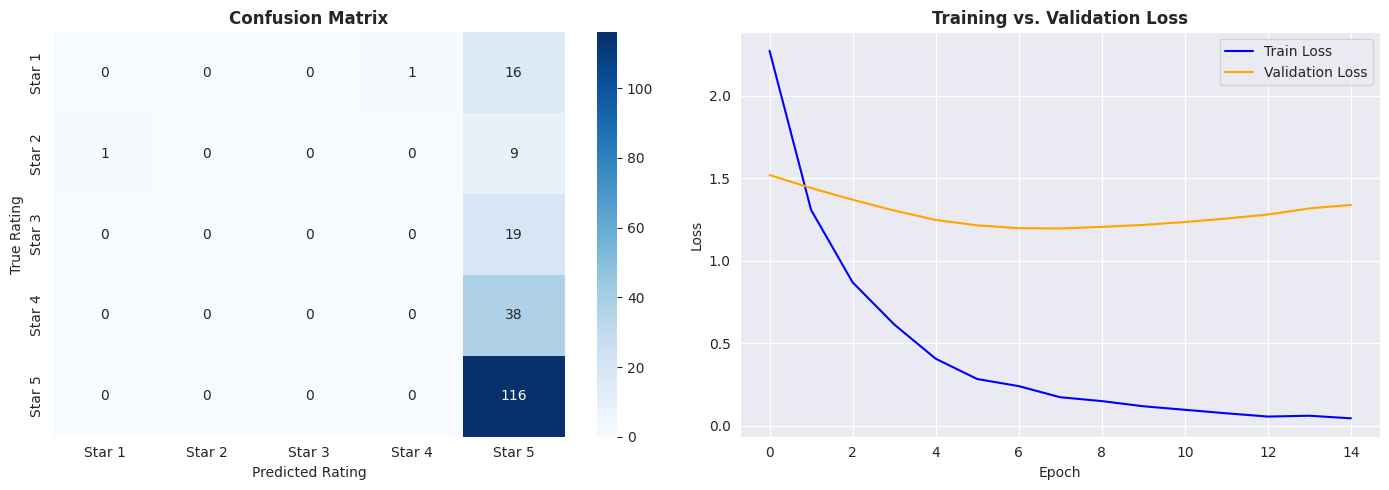

In [62]:
# Visualizations, Confusion Matrix & Loss Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names, ax=axes[0])
axes[0].set_title('Confusion Matrix', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Rating')
axes[0].set_ylabel('True Rating')

# Loss Curve
axes[1].plot(history.history['loss'], label='Train Loss', color='blue')
axes[1].plot(history.history['val_loss'], label='Validation Loss', color='orange')
axes[1].set_title('Training vs. Validation Loss', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Class Performance Insights:** Extreme rating classes (1-Star and 5 Star) are typically predicted with higher precision and recall because their wording is distinctly polarized ("terrible", "waste of money" vs. "excellent", "highly recommend"). Moderate ratings (2 Star and 4 Star) are harder to classify because customer language in middle tiers often contains mixed sentiments (e.g., praising quality while complaining about price).

**Architecture & Regularization Choice:** Incorporating Dropout ($0.3-0.4$) and Batch Normalization prevents the dense layers from quickly memorizing TF-IDF feature noise, ensuring training and validation loss decay smoothly without severe overfitting.